# Thành viên 3 – Feature Engineering (Kỹ Nghệ Đặc Trưng)

**Mục tiêu:** Tạo 22 đặc trưng miền (Domain-specific Features) mới từ 24 cột chuẩn ban đầu, mở rộng bộ dữ liệu lên 46 cột để phục vụ huấn luyện các mô hình Machine Learning ở các phần tiếp theo (TV4 & TV5).

---

### Bảng Tổng Quan 22 Đặc Trưng Mới Được Tạo

| STT | Tên đặc trưng | Nhóm đặc trưng | Công thức / Quy tắc tính | Ý nghĩa nghiệp vụ |
| :---: | :--- | :--- | :--- | :--- |
| 1 | `scheduled_hour_num` | Chu kỳ thời gian | $\text{Hour} + \frac{\text{Minute}}{60.0}$ | Đổi giờ bay lịch trình về dạng số thực liên tục (0.0 - 23.98) |
| 2 | `hour_sin` | Chu kỳ thời gian | $\sin\left(\frac{2\pi \times \text{scheduled\_hour\_num}}{24}\right)$ | Biểu diễn chu kỳ 24 giờ (thành phần sine) |
| 3 | `hour_cos` | Chu kỳ thời gian | $\cos\left(\frac{2\pi \times \text{scheduled\_hour\_num}}{24}\right)$ | Biểu diễn chu kỳ 24 giờ (thành phần cosine) |
| 4 | `dow_sin` | Chu kỳ thời gian | $\sin\left(\frac{2\pi \times \text{dayofweek}}{7}\right)$ | Biểu diễn chu kỳ 7 ngày trong tuần (thành phần sine) |
| 5 | `dow_cos` | Chu kỳ thời gian | $\cos\left(\frac{2\pi \times \text{dayofweek}}{7}\right)$ | Biểu diễn chu kỳ 7 ngày trong tuần (thành phần cosine) |
| 6 | `is_peak_hour` | Tải sân bay | Cờ $1$ nếu thuộc khung giờ $06h00-09h30$ hoặc $17h00-20h30$ | Khung giờ cao điểm ùn ứ cất/hạ cánh |
| 7 | `is_heavy_traffic` | Tải sân bay | Cờ $1$ nếu $\text{airport\_load} > 28$ chuyến/giờ | Đánh dấu thời điểm sân bay quá tải nghiêm trọng |
| 8 | `is_rain` | Thời tiết | Cờ $1$ nếu $\text{precipitation} > 0.1\text{ mm}$ | Có mưa tại thời điểm quan sát |
| 9 | `is_heavy_rain` | Thời tiết | Cờ $1$ nếu $\text{precipitation} > 2.5\text{ mm}$ | Mưa lớn ảnh hưởng đến cất/hạ cánh |
| 10 | `is_high_wind` | Thời tiết | Cờ $1$ nếu $\text{wind\_gusts\_10m} > 30.0\text{ km/h}$ | Gió giật mạnh nguy cơ hoãn bay |
| 11 | `is_severe_wind` | Thời tiết | Cờ $1$ nếu $\text{wind\_gusts\_10m} > 50.0\text{ km/h}$ | Gió cực đoan gây gián đoạn đường băng |
| 12 | `is_low_vis` | Thời tiết | Cờ $1$ nếu $\text{visibility} < 5000.0\text{ m}$ | Tầm nhìn thấp hạn chế quan sát |
| 13 | `is_storm` | Thời tiết | Cờ $1$ nếu $\text{weather\_code} \ge 95$ | Hiện tượng dông bão / sấm sét WMO |
| 14 | `weather_hazard_score` | Thời tiết | Điểm tổng hợp liên tục $0.0 \rightarrow 1.0$ từ Mưa + Gió + Tầm nhìn + Bão | Thang điểm nguy cơ thời tiết đa biến |
| 15 | `carrier_category` | Hãng & Tuyến bay | Phân loại `VN` $\rightarrow$ FSC, `VJ`/`BL` $\rightarrow$ LCC, `QH` $\rightarrow$ HYBRID, ... | Mô hình vận hành của hãng hàng không |
| 16 | `is_golden_triangle` | Hãng & Tuyến bay | Cờ $1$ cho các tuyến kết nối SGN - HAN - DAD | Đường bay trục vàng mật độ cao nhất VN |
| 17 | `is_holiday_flag` | Bối cảnh | Cờ $0/1$ ép kiểu từ biến boolean `is_holiday` | Ngày lễ tết nhu cầu đi lại tăng vọt |
| 18 | `is_weekend_flag` | Bối cảnh | Cờ $1$ nếu ngày bay rơi vào Thứ 7 hoặc Chủ Nhật | Cuối tuần mật độ du lịch cao |
| 19 | `is_domestic_flag` | Bối cảnh | Cờ $1$ nếu `route_type` là `domestic` | Chuyến bay nội địa so với quốc tế |
| 20 | `is_departure` | Bối cảnh | Cờ $1$ nếu `direction` là `DEPARTURES` | Chiều xuất phát hay chiều hạ cánh |
| 21 | `load_x_weather` | Tương tác | $\text{airport\_load} \times \text{weather\_hazard\_score}$ | Sân bay đông kết hợp thời tiết xấu nhân đôi rủi ro |
| 22 | `peak_x_rain` | Tương tác | $\text{is\_peak\_hour} \times \text{is\_rain}$ | Cao điểm gặp mưa gây chậm chuyến dây chuyền |

> **Nguyên tắc Chống Rò Rỉ Thông Tin (Data Leakage Guard):** Tuyệt đối không dùng 4 cột rò rỉ (`delay_min`, `actual_time`, `status`, `status_detail`) để tính toán đặc trưng. Cột `status_clean` chỉ được dùng làm biến mục tiêu để phân tích tương quan ở bước sau khi các đặc trưng đã hoàn thành.

## 1. Nạp dữ liệu và xây dựng 22 đặc trưng

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd

# Tìm thư mục gốc dự án chứa config.py
PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "config.py").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError(
            "Không tìm thấy config.py. "
            "Hãy kiểm tra cấu trúc thư mục dự án."
        )
    PROJECT_ROOT = PROJECT_ROOT.parent

# Thêm thư mục gốc vào Python import path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import modules
from config import FILE_CLEANED, CLEANED_FIELDS
from features.features import build_engineered_features, FILE_FEATURES

# Đọc dữ liệu
if FILE_CLEANED.exists():
    raw_df = pd.read_csv(FILE_CLEANED)
    print(f'Dữ liệu thật: {len(raw_df):,} dòng')
else:
    # Dữ liệu mô phỏng để kiểm tra logic
    n = 120

    raw_df = pd.DataFrame({
        'leg_key': [f'VN{i:04d}|2026-10-{(i%28)+1:02d}|SGN>HAN' for i in range(n)],
        'flight_date': [f'2026-10-{(i%28)+1:02d}' for i in range(n)],
        'flight_no': [f'VN{i:04d}' for i in range(n)],
        'airline_code': ['VN' if i%2==0 else 'VJ' for i in range(n)],
        'origin': ['SGN']*n,
        'destination': ['HAN']*n,
        'route_type': ['domestic']*n,
        'airport': ['SGN']*n,
        'direction': ['DEPARTURES']*n,
        'scheduled_time': [f'{(i%24):02d}:{(i%4)*15:02d}' for i in range(n)],
        'actual_time': ['08:10']*n,
        'delay_min': [10.0]*n,
        'time_slot': ['06h-12h']*n,
        'day_type': ['weekday']*n,
        'is_holiday': [False]*n,
        'airport_load': [10+i%35 for i in range(n)],
        'precipitation': [float(i%8)/2 for i in range(n)],
        'wind_gusts_10m': [10.0+i%50 for i in range(n)],
        'visibility': [10000.0-(i%8)*800 for i in range(n)],
        'weather_code': [95 if i%17==0 else 0 for i in range(n)],
        'status': ['Departed On-Time']*n,
        'status_detail': ['departed_on_time']*n,
        'status_clean': ['delayed' if i%4==0 else 'on_time' for i in range(n)],
        'source': ['guide_sgn']*n
    })

    raw_df = raw_df[CLEANED_FIELDS]

    print('Không tìm thấy CSV; đang dùng synthetic data để minh họa.')

# Feature Engineering
feat_df = build_engineered_features(raw_df)

new_cols = [c for c in feat_df.columns if c not in raw_df.columns]

print(
    f'{len(raw_df.columns)} cột ban đầu -> '
    f'{len(feat_df.columns)} cột sau FE; '
    f'{len(new_cols)} đặc trưng mới'
)

print(new_cols)

# Kiểm tra số lượng features
assert len(new_cols) == 22 and feat_df.shape[1] == 46, (
    f"Lỗi số lượng feature: "
    f"{len(new_cols)} feature mới, "
    f"tổng {feat_df.shape[1]} cột"
)

display(
    feat_df[
        [
            'scheduled_time',
            'hour_sin',
            'hour_cos',
            'dow_sin',
            'dow_cos',
            'weather_hazard_score',
            'is_peak_hour',
            'airport_load',
            'load_x_weather'
        ]
    ].head()
)

Dữ liệu thật: 13,965 dòng
24 cột ban đầu -> 46 cột sau FE; 22 đặc trưng mới
['scheduled_hour_num', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_peak_hour', 'is_heavy_traffic', 'is_rain', 'is_heavy_rain', 'is_high_wind', 'is_severe_wind', 'is_low_vis', 'is_storm', 'weather_hazard_score', 'carrier_category', 'is_golden_triangle', 'is_holiday_flag', 'is_weekend_flag', 'is_domestic_flag', 'is_departure', 'load_x_weather', 'peak_x_rain']


,scheduled_time,hour_sin,hour_cos,dow_sin,dow_cos,weather_hazard_score,is_peak_hour,airport_load,load_x_weather
0,12:42,-0.182236,-0.983255,0.974928,-0.222521,0.1002,0,15.0,1.5030
1,12:42,-0.182236,-0.983255,0.974928,-0.222521,0.2656,0,27.0,7.1712
2,12:42,-0.182236,-0.983255,0.974928,-0.222521,0.1002,0,15.0,1.5030
3,12:42,-0.182236,-0.983255,0.974928,-0.222521,0.2656,0,27.0,7.1712
4,12:42,-0.182236,-0.983255,0.974928,-0.222521,0.2109,0,19.0,4.0071


## 2. Giải thích nhóm đặc trưng chu kỳ thời gian

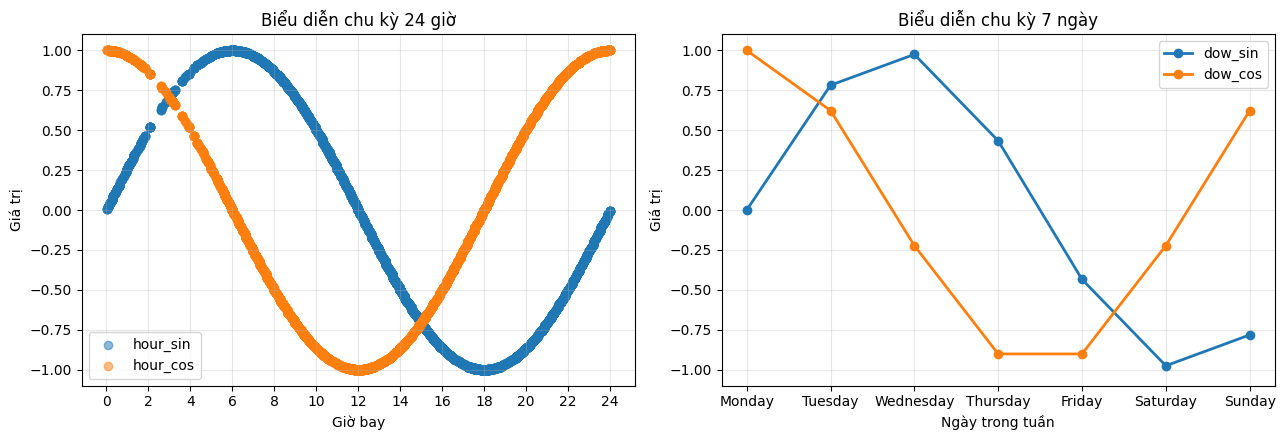

Số giờ bay khác nhau: 313
Số thứ trong tuần khác nhau: 7
Số ngày bay khác nhau: 20

Giá trị chu kỳ 7 ngày:
      dow_sin   dow_cos
day                    
0    0.000000  1.000000
1    0.781831  0.623490
2    0.974928 -0.222521
3    0.433884 -0.900969
4   -0.433884 -0.900969
5   -0.974928 -0.222521
6   -0.781831  0.623490


In [2]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ==================================================
# 1. CHU KỲ 24 GIỜ
# ==================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Vẽ chu kỳ 24 giờ
axes[0].scatter(
    feat_df['scheduled_hour_num'],
    feat_df['hour_sin'],
    alpha=0.5,
    label='hour_sin'
)

axes[0].scatter(
    feat_df['scheduled_hour_num'],
    feat_df['hour_cos'],
    alpha=0.5,
    label='hour_cos'
)

axes[0].set(
    title='Biểu diễn chu kỳ 24 giờ',
    xlabel='Giờ bay',
    ylabel='Giá trị'
)

axes[0].set_xticks(range(0, 25, 2))
axes[0].set_ylim(-1.1, 1.1)
axes[0].legend()
axes[0].grid(alpha=0.3)


# ==================================================
# 2. CHU KỲ 7 NGÀY
# ==================================================

# Chuyển ngày bay sang datetime
flight_dates = pd.to_datetime(feat_df['flight_date'])

# Thứ trong tuần: Monday = 0, Sunday = 6
dow = flight_dates.dt.dayofweek

# Tạo DataFrame chứa hai feature tuần hoàn
dow_df = pd.DataFrame({
    'day': dow,
    'dow_sin': feat_df['dow_sin'],
    'dow_cos': feat_df['dow_cos']
})

# Tổng hợp giá trị theo từng thứ
dow_summary = (
    dow_df.groupby('day')[['dow_sin', 'dow_cos']]
    .mean()
    .reindex(range(7))
)

# Vẽ hai đường chu kỳ
axes[1].plot(
    dow_summary.index,
    dow_summary['dow_sin'],
    marker='o',
    linewidth=2,
    label='dow_sin'
)

axes[1].plot(
    dow_summary.index,
    dow_summary['dow_cos'],
    marker='o',
    linewidth=2,
    label='dow_cos'
)

axes[1].set(
    title='Biểu diễn chu kỳ 7 ngày',
    xlabel='Ngày trong tuần',
    ylabel='Giá trị'
)

axes[1].set_xticks(range(7))
axes[1].set_xticklabels([
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
])

axes[1].set_ylim(-1.1, 1.1)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ==================================================
# 3. KIỂM TRA GIÁ TRỊ FEATURE
# ==================================================

assert feat_df[
    ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos']
].dropna().apply(
    lambda col: col.between(-1, 1).all()
).all()

print("Số giờ bay khác nhau:",
      feat_df['scheduled_hour_num'].nunique())

print("Số thứ trong tuần khác nhau:",
      dow.nunique())

print("Số ngày bay khác nhau:",
      flight_dates.nunique())

print("\nGiá trị chu kỳ 7 ngày:")
print(dow_summary)


## 3. Điểm nguy cơ thời tiết và tải sân bay

,count,mean,std,min,25%,50%,75%,max
precipitation,13916.0,0.259809,0.840825,0.0,0.0000,0.0000,0.1000,12.50
wind_gusts_10m,13916.0,18.862619,7.624433,0.7,13.0000,18.0000,24.1000,48.20
visibility,13916.0,13495.776085,7429.463599,160.0,7760.0000,12920.0000,17760.0000,36860.00
weather_code,13916.0,23.384306,27.609432,0.0,1.0000,3.0000,51.0000,95.00
weather_hazard_score,13965.0,0.069275,0.093768,0.0,0.0044,0.0418,0.0906,0.82
is_rain,13965.0,0.239814,0.426985,0.0,0.0000,0.0000,0.0000,1.00
is_heavy_rain,13965.0,0.020981,0.143326,0.0,0.0000,0.0000,0.0000,1.00
is_high_wind,13965.0,0.073469,0.260915,0.0,0.0000,0.0000,0.0000,1.00
is_severe_wind,13965.0,0.000000,0.000000,0.0,0.0000,0.0000,0.0000,0.00
is_low_vis,13965.0,0.116720,0.321098,0.0,0.0000,0.0000,0.0000,1.00


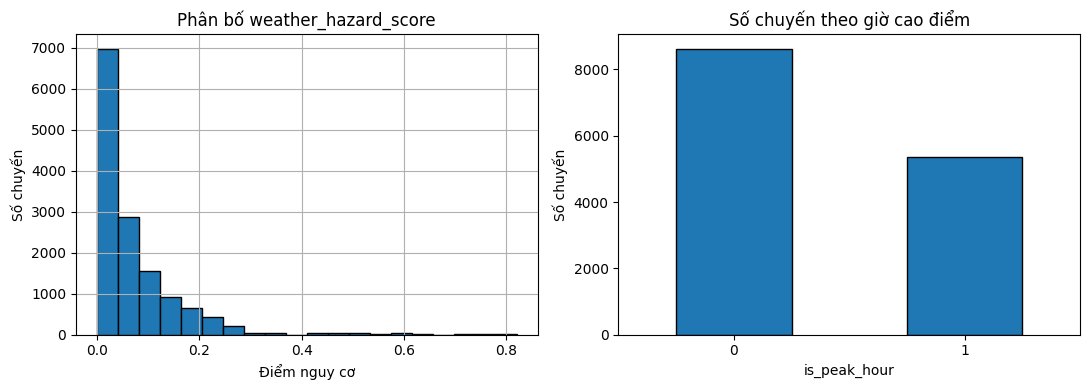

In [3]:
weather_cols=['precipitation','wind_gusts_10m','visibility','weather_code','weather_hazard_score','is_rain','is_heavy_rain','is_high_wind','is_severe_wind','is_low_vis','is_storm']
display(feat_df[weather_cols].describe().T)

fig, axes=plt.subplots(1,2,figsize=(11,4))
feat_df['weather_hazard_score'].hist(bins=20,ax=axes[0],edgecolor='black'); axes[0].set(title='Phân bố weather_hazard_score',xlabel='Điểm nguy cơ',ylabel='Số chuyến')
feat_df['is_peak_hour'].value_counts().sort_index().plot(kind='bar',ax=axes[1],edgecolor='black'); axes[1].set(title='Số chuyến theo giờ cao điểm',xlabel='is_peak_hour',ylabel='Số chuyến'); axes[1].tick_params(axis='x',rotation=0)
plt.tight_layout(); plt.show()
assert feat_df['weather_hazard_score'].between(0,1).all()

## 4. Kiểm tra tương quan giữa đặc trưng mới và tỷ lệ trễ

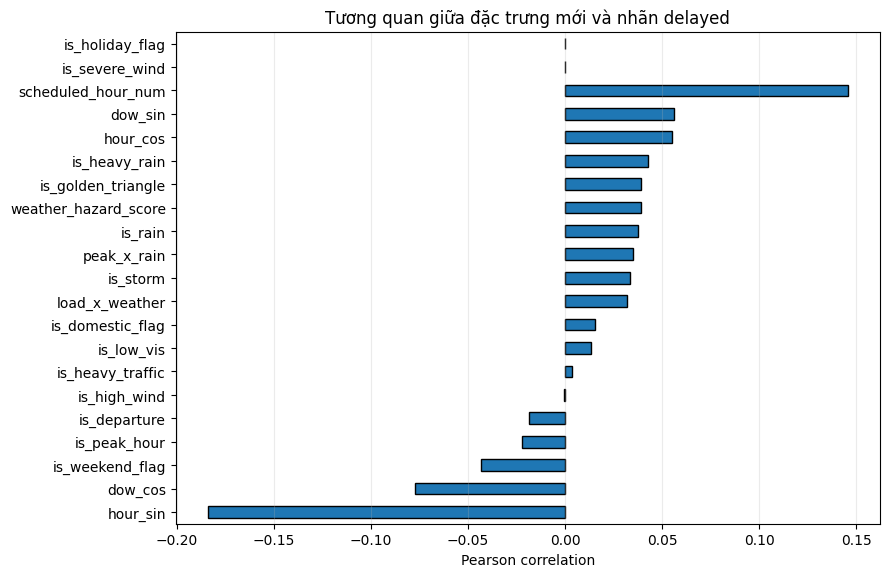

,Correlation
hour_sin,-0.184086
dow_cos,-0.077141
is_weekend_flag,-0.043420
is_peak_hour,-0.022227
is_departure,-0.018414
is_high_wind,-0.000307
is_heavy_traffic,0.003774
is_low_vis,0.013150
is_domestic_flag,0.015235
load_x_weather,0.032016


Lưu ý: tương quan không chứng minh quan hệ nhân quả; dữ liệu mô phỏng chỉ để minh họa.


In [4]:
# status_clean chỉ dùng làm biến mục tiêu để phân tích sau khi tạo feature.
feat_df['is_delayed_for_analysis']=(feat_df['status_clean']=='delayed').astype(int)
feature_numeric=[c for c in new_cols if pd.api.types.is_numeric_dtype(feat_df[c])]
corr=feat_df[feature_numeric+['is_delayed_for_analysis']].corr(numeric_only=True)['is_delayed_for_analysis'].drop('is_delayed_for_analysis').sort_values()
plt.figure(figsize=(9,max(5,len(corr)*.28)))
corr.plot(kind='barh',edgecolor='black'); plt.title('Tương quan giữa đặc trưng mới và nhãn delayed')
plt.xlabel('Pearson correlation'); plt.grid(axis='x',alpha=.25); plt.tight_layout(); plt.show()
display(corr.to_frame('Correlation'))
print('Lưu ý: tương quan không chứng minh quan hệ nhân quả; dữ liệu mô phỏng chỉ để minh họa.')

## 5. Kiểm tra Data Leakage và lưu dữ liệu

In [5]:
FORBIDDEN={'delay_min','actual_time','status','status_detail'}
# Thay đổi các cột rò rỉ không được làm thay đổi bất kỳ đặc trưng mới nào.
changed=raw_df.copy()
for c in FORBIDDEN:
    if c in changed.columns:
        changed[c]='__CHANGED__'
feat_changed=build_engineered_features(changed)
pd.testing.assert_frame_equal(feat_df[new_cols],feat_changed[new_cols])
print('PASS: 4 cột leakage không ảnh hưởng đến 22 đặc trưng mới.')

if FILE_CLEANED.exists():
    FILE_FEATURES.parent.mkdir(parents=True,exist_ok=True)
    feat_df.to_csv(FILE_FEATURES,index=False,encoding='utf-8-sig')
    print(f'Đã lưu {feat_df.shape[0]:,} dòng x {feat_df.shape[1]} cột -> {FILE_FEATURES}')
else:
    print('Không lưu synthetic data vào data/processed; hãy chạy lại khi có flights_cleaned_global.csv.')

PASS: 4 cột leakage không ảnh hưởng đến 22 đặc trưng mới.
Đã lưu 13,965 dòng x 47 cột -> D:\datamining_nhom8_updated\data\processed\flights_features.csv


## 6. Kết luận và bàn giao

- 22 cột mới bao gồm chu kỳ thời gian, thời tiết, tải sân bay/giờ cao điểm, tuyến bay/hãng và biến tương tác.
- Kết quả đúng theo hợp đồng: 24 cột đầu vào + 22 cột mới = 46 cột.
- File bàn giao: `data/processed/flights_features.csv`.
- TV4 tiếp tục loại bỏ các cột leakage/ID, mã hóa biến phân loại và chuẩn hóa biến liên tục; không fit scaler/encoder trên toàn bộ dữ liệu trước khi chia train/test.